<a href="https://colab.research.google.com/github/morenomarisa/AnonimizadorRegex/blob/main/RegexMatrizes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **# Experimento reconhecimento de dados pessoais usando REGEX**

**Bloco 1: Importação de bibliotecas**

In [62]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import re
import decimal


**Bloco 2: Carregamento dos dados**

In [63]:
# Carrega os arquivos Excel com os dados de extração e o gabarito
extracao = pd.read_excel(r"/content/drive/MyDrive/ProjetosCod/Anonimizador_Regex/Analise-Anonimizador-master/BOS.xlsx")
gabarito = pd.read_excel(r"/content/drive/MyDrive/ProjetosCod/Anonimizador_Regex/Analise-Anonimizador-master/trezentinhos-GABARITO-Valor Monetario sem virgula e simbolo.xlsx")


**Bloco 3: Definição de funções auxiliares**

In [64]:
def list_subtraction(x, y):
    return [item for item in x if item not in y]

def list_intersection(x, y):
    return [item for item in x if item in y]

def tokenize(text):
    RE_TOKEN = re.compile(
        r"""([#]?[@\w'’\+\-.,]*[\w][$]?|[:;<]\-?[\)\(3])""", re.VERBOSE)
    return RE_TOKEN.findall(text)

def count_tokens_number(df, name_column):
    count_list = []
    for relato in df[name_column]:
        count = 0
        if pd.notnull(relato):
            tokenized_relato = tokenize(str(relato))
            for token in tokenized_relato:
                count += 1
            count_list.append(count)
    return count_list

def count_tokens_symbol(df, name_column):
    tokens_list = []
    for relato in df[name_column]:
        tokenized_relato = tokenize(str(relato))
        for token in tokenized_relato:
            tokens_list.append(token)
    return tokens_list

def calculations_of_classifications(data_set, true, predicted):
    tp, tn, fp, fn = 0, 0, 0, 0
    true_predicted = set(true + predicted)
    true = list(set(true))
    predicted = list(set(predicted))
    vector_ext = [predicted.count(x) for x in true_predicted]
    vector_gab = [true.count(x) for x in true_predicted]
    vector_result = [x - y for x, y in zip(vector_gab, vector_ext)]
    for x in vector_result:
        if x < 0:
            fp += 1
        if x > 0:
            fn += 1
        if x == 0:
            tp += 1
    tn = len(data_set) - fn - fp - tp
    return tp, tn, fp, fn

def sum_of_classifications(extracao_alvo, gabarito_alvo, extracao_relato=extracao["relato"], n_bop=extracao["n_bop"]):
    tp, tn, fp, fn = 0, 0, 0, 0
    gabarito = 0
    for n_bop_relato, resultado_extracao_relato, resultado_extracao_alvo, resultado_gabarito_alvo in zip(n_bop, extracao_relato, extracao_alvo, gabarito_alvo.astype(str)):
        resultado_extracao_relato_tokenizado = tokenize(resultado_extracao_relato)
        total_tokens = len(resultado_extracao_relato_tokenizado)
        resultado_extracao_alvo_tokenizado = tokenize(resultado_extracao_alvo)
        resultado_gabarito_alvo_tokenizado = tokenize(resultado_gabarito_alvo)
        aux_tp, aux_tn, aux_fp, aux_fn = calculations_of_classifications(data_set=resultado_extracao_relato_tokenizado, true=resultado_gabarito_alvo_tokenizado, predicted=resultado_extracao_alvo_tokenizado)
        if aux_fn:
            print(f'N_BOP: {n_bop_relato} | Extraído: {resultado_extracao_alvo_tokenizado} | Gabarito: {resultado_gabarito_alvo_tokenizado}')
            print(f'TP: {aux_tp} | FP: {aux_fp} | TN: {aux_tn} | FN: {aux_fn}')
            print(f'TOTAL TOKENS: {total_tokens}')
            print(f'TOKENS TOTAIS: {set(resultado_extracao_relato_tokenizado)}')
            print('\n')
            gabarito += len(resultado_gabarito_alvo_tokenizado)
        tp += aux_tp
        tn += aux_tn
        fp += aux_fp
        fn += aux_fn
    print(gabarito)
    return tp, tn, fp, fn

def calculations_of_precision_recall_score(tp, tn, fp, fn):
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)
    f1_score = 2 * precision * recall / (precision + recall)
    return precision, recall, f1_score

def round_down(number) -> str:
    decimal.getcontext().rounding = decimal.ROUND_DOWN
    round_down = decimal.Decimal(number)
    return '{:.2f}'.format(round_down)




**Bloco 4: Criação da pasta 'Análises' e Função de Plotagem**

In [67]:
# Verifica se a pasta 'Análises' existe, caso contrário, cria a pasta.
if not os.path.exists('Análises'):
    os.makedirs('Análises')

def plot_graph(nome, precision, recall, f1_score, tp, tn, fp, fn):
    labels = ['correto', 'errado']
    cm = np.array([[tn, fp], [fn, tp]])
    group_names = ["True Neg", "False Pos", "False Neg", "True Pos"]
    group_counts = ["{0:0.0f}".format(value) for value in cm.flatten()]
    labels = [f"{v1}\n{v2}" for v1, v2 in zip(group_names, group_counts)]
    labels = np.asarray(labels).reshape(2, 2)
    accuracy = np.trace(cm) / float(np.sum(cm))
    precision = cm[1, 1] / sum(cm[:, 1])
    recall = cm[1, 1] / sum(cm[1, :])
    f1_score = 2 * precision * recall / (precision + recall)
    stats_text = "\n\nAccuracy={:0.6f}\nPrecision={:0.6f}\nRecall={:0.6f}\nF1 Score={:0.6f}".format(accuracy, precision, recall, f1_score)
    sns.heatmap(cm, cmap='binary', fmt='', annot=labels)
    sns.despine(left=False, right=False, top=False, bottom=False)
    plt.xlabel('Classe predito' + stats_text)
    plt.ylabel('Classe verdadeiro')
    plt.title('{}'.format(nome), fontsize=12, fontweight='bold')

    # Salva a figura na pasta 'Análises'
    plt.savefig(f'Análises/{nome[:10]}.png', dpi=600, bbox_inches='tight')
    plt.figure()


**Bloco 5: Execução das análises e geração das matrizes de confusão**

N_BOP: 00615/2021.100191-1 | Extraído: ['MANDA', 'FARIAS', 'SERIA', 'POLO', 'WILLIAN'] | Gabarito: ['WILLIAN', 'DI', 'FARIAS']
TP: 2 | FP: 3 | TN: 194 | FN: 1
TOTAL TOKENS: 200
TOKENS TOTAIS: {'BASTASSE', 'AFIRMA', 'POIS', 'DI', 'ALUNOS', 'HA', 'EXERCE', 'PESSOA', 'A', '04', 'DEPOENTE', 'FARIAS', 'COISAS', 'PEDIR', 'WILLIAN', 'FATOS', 'ESTA', '99669-6330', 'AMBOS', 'DECLARANTE', 'ENTRE', 'LABORAIS', 'INFORMAR', 'TAMBEM', 'CURSO', 'CHAMANDO-A', 'NUNCA', 'DADO', 'UM', 'DESDE', 'NO', 'AINDA', 'ANOS', 'DIZENDO', 'NUDES', 'PROFESSORA', 'AOS', 'PROVIDENCIAS', 'DEVIDAS', 'QUANTOS', 'SUA', 'CUNHO', 'CACETEIRA', 'REDE', '98027-0161', 'ACIMA', 'ATRAVES', 'AMIGO', 'NUMERO', 'TELEFONE', 'E', 'GOSTAM', 'REFERIDAS', 'ATIVIDADES', 'SOLICITANDO', 'TROCAS', 'PRINTS', 'ENDERECO', 'INTERLOCUTOR', 'GENITALIA', 'MENSAGENS', 'QUEM', 'MESMO', 'NOME', 'POREM', 'APOS', 'VEM', 'MOMENTO', 'PORTUGUESA', 'DAS', 'SUAS', 'QUALIFICADA', 'EM', 'DENEGRINDO', '02', 'DECLINA', 'DA', 'PARA', 'RECEBENDO', 'TEMPORARIAMENTE'

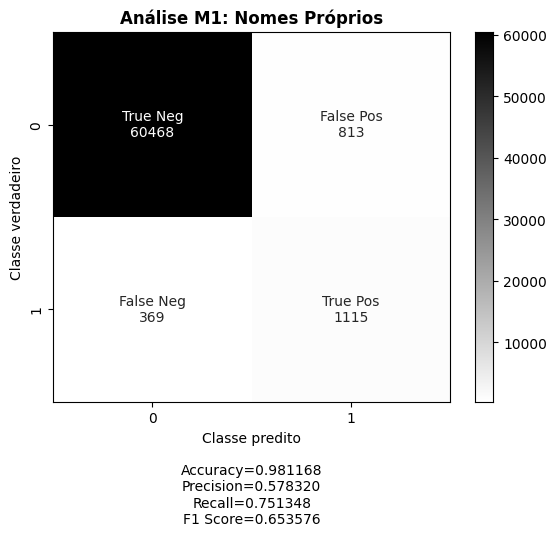

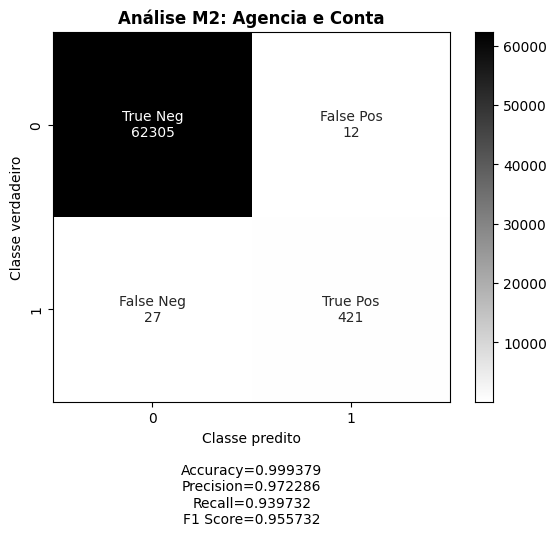

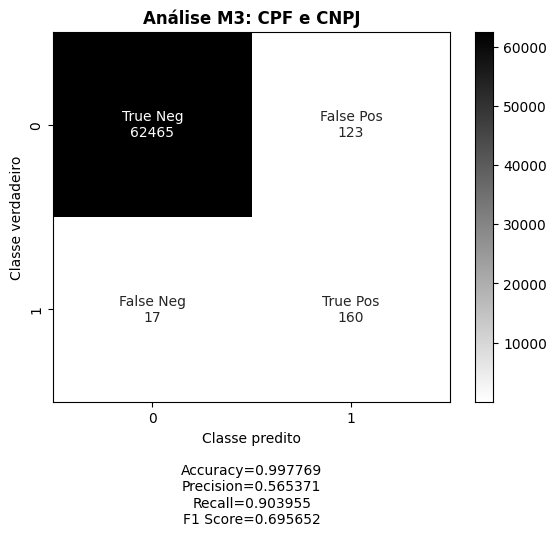

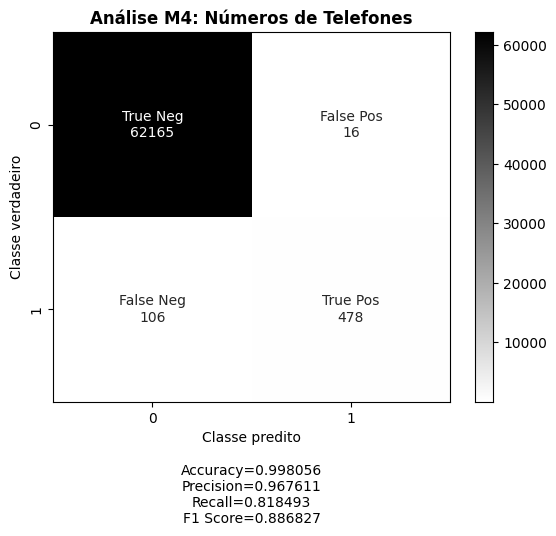

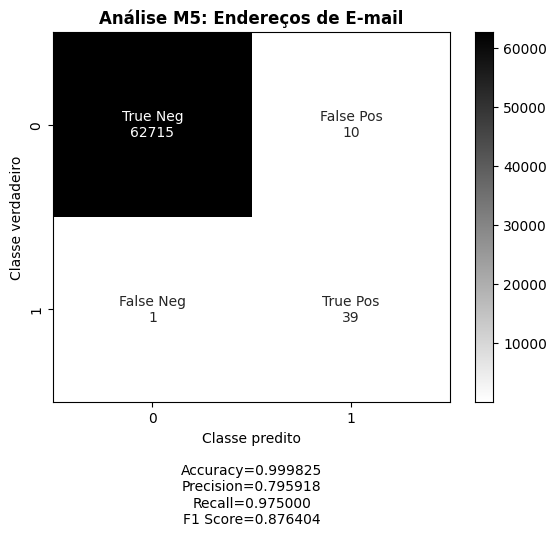

<Figure size 640x480 with 0 Axes>

In [68]:
# Definição das colunas e títulos para análise
title_names = ["Nomes Próprios", "Agencia e Conta", "CPF e CNPJ", "Números de Telefones", "Endereços de E-mail"]
col_names = ["NOMES", "AGENCIA E CONTA", "CPF/CNPJ", "TELEFONE", "EMAIL"]

# Loop para gerar as matrizes de confusão e calcular as métricas de avaliação
for index in range(len(col_names)):
    tp, tn, fp, fn = sum_of_classifications(extracao[col_names[index]].fillna(''), gabarito[col_names[index]].fillna(''))
    precision, recall, f1_score = calculations_of_precision_recall_score(tp, tn, fp, fn)
    print(f"Análise M{index+1}: {title_names[index]}")
    print(f"Precision: {precision:.6f}, Recall: {recall:.6f}, F1_Score: {f1_score:.6f}")
    plot_graph(f"Análise M{index+1}: {title_names[index]}", precision, recall, f1_score, tp, tn, fp, fn)


**Bloco 6: Resultados e impressões (opcional)**

In [69]:
# Caso deseje imprimir os resultados de cada análise após a execução do loop
for index in range(len(col_names)):
    tp, tn, fp, fn = sum_of_classifications(extracao[col_names[index]].fillna(''), gabarito[col_names[index]].fillna(''))
    precision, recall, f1_score = calculations_of_precision_recall_score(tp, tn, fp, fn)
    print(f"Análise M{index+1}: {title_names[index]}")
    print(f"Precision: {precision:.2f}, Recall: {recall:.2f}, F1_Score: {f1_score:.2f}")


N_BOP: 00615/2021.100191-1 | Extraído: ['MANDA', 'FARIAS', 'SERIA', 'POLO', 'WILLIAN'] | Gabarito: ['WILLIAN', 'DI', 'FARIAS']
TP: 2 | FP: 3 | TN: 194 | FN: 1
TOTAL TOKENS: 200
TOKENS TOTAIS: {'BASTASSE', 'AFIRMA', 'POIS', 'DI', 'ALUNOS', 'HA', 'EXERCE', 'PESSOA', 'A', '04', 'DEPOENTE', 'FARIAS', 'COISAS', 'PEDIR', 'WILLIAN', 'FATOS', 'ESTA', '99669-6330', 'AMBOS', 'DECLARANTE', 'ENTRE', 'LABORAIS', 'INFORMAR', 'TAMBEM', 'CURSO', 'CHAMANDO-A', 'NUNCA', 'DADO', 'UM', 'DESDE', 'NO', 'AINDA', 'ANOS', 'DIZENDO', 'NUDES', 'PROFESSORA', 'AOS', 'PROVIDENCIAS', 'DEVIDAS', 'QUANTOS', 'SUA', 'CUNHO', 'CACETEIRA', 'REDE', '98027-0161', 'ACIMA', 'ATRAVES', 'AMIGO', 'NUMERO', 'TELEFONE', 'E', 'GOSTAM', 'REFERIDAS', 'ATIVIDADES', 'SOLICITANDO', 'TROCAS', 'PRINTS', 'ENDERECO', 'INTERLOCUTOR', 'GENITALIA', 'MENSAGENS', 'QUEM', 'MESMO', 'NOME', 'POREM', 'APOS', 'VEM', 'MOMENTO', 'PORTUGUESA', 'DAS', 'SUAS', 'QUALIFICADA', 'EM', 'DENEGRINDO', '02', 'DECLINA', 'DA', 'PARA', 'RECEBENDO', 'TEMPORARIAMENTE'

**Bloco 7: Matrizes combinadas em uma única imagem**

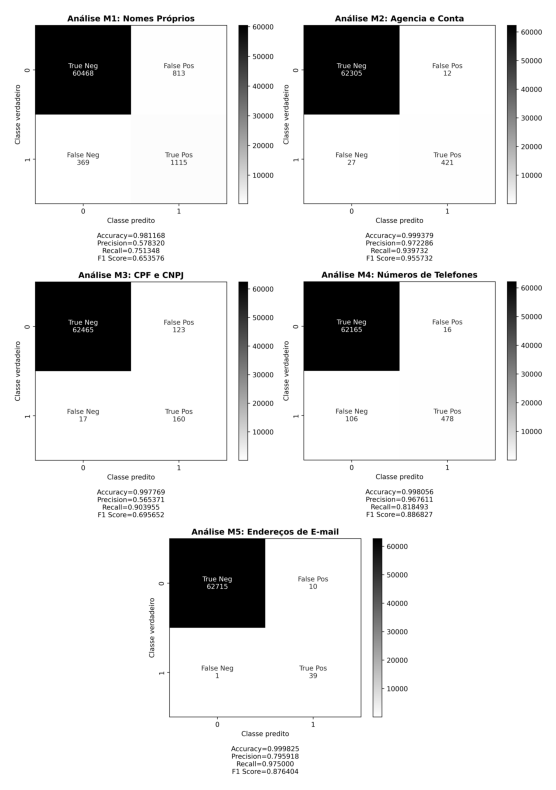

In [70]:
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

# Lista de caminhos para as imagens geradas
image_paths = [f"Análises/Análise M{index+1}.png" for index in range(len(title_names))]

# Abrir todas as imagens
images = [Image.open(image_path) for image_path in image_paths]

# Determinar o tamanho das imagens (assume que todas as imagens têm o mesmo tamanho)
width, height = images[0].size

# Determinar a grade para a disposição das imagens
columns = 2
rows = 3  # 2 para as primeiras 4 matrizes + 1 linha para a última matriz centralizada

# Criar uma nova imagem com fundo branco que vai conter todas as imagens
combined_image = Image.new('RGB', (width * columns, height * rows), (255, 255, 255))

# Colar as primeiras quatro imagens
for index, image in enumerate(images[:-1]):
    x = (index % columns) * width
    y = (index // columns) * height
    combined_image.paste(image, (x, y))

# Adicionar a última matriz centralizada na linha inferior
last_image = images[-1]
x_center = (combined_image.width - width) // 2
y_last = 2 * height  # Última linha
combined_image.paste(last_image, (x_center, y_last))

# Salvar a imagem combinada
combined_image.save("Análises/combined_confusion_matrices.png")

# Exibir a imagem combinada
plt.figure(figsize=(10, 10))
plt.imshow(combined_image)
plt.axis('off')  # Esconde os eixos
plt.show()


**Tabela Resultados Regex**

In [71]:
# Definição das colunas e títulos para análise
title_names = ["Nomes Próprios", "Agencia e Conta", "CPF e CNPJ", "Números de Telefones", "Endereços de E-mail"]
col_names = ["NOMES", "AGENCIA E CONTA", "CPF/CNPJ", "TELEFONE", "EMAIL"]

# Função para calcular métricas
def calculations_of_precision_recall_score(tp, tn, fp, fn):
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    accuracy = (tp + tn) / (tp + tn + fp + fn) if (tp + tn + fp + fn) > 0 else 0
    return precision, recall, f1_score, accuracy

# Lista para armazenar os resultados das métricas
results = []

# Loop para gerar as métricas de avaliação e armazenar os resultados
for index in range(len(col_names)):
    tp, tn, fp, fn = sum_of_classifications(extracao[col_names[index]].fillna(''), gabarito[col_names[index]].fillna(''))
    accuracy, precision, recall, f1_score = calculations_of_precision_recall_score(tp, tn, fp, fn)

    # Armazenar os resultados no DataFrame
    results.append({
        "Matriz": f"M{index+1}",
        #"Título": title_names[index],
        "Acurácia": f"{accuracy:.6f}",
        "Precisão": f"{precision:.6f}",
        "Recall": f"{recall:.6f}",
        "F1_Score": f"{f1_score:.6f}"
    })

# Criar um DataFrame com os resultados
results_df = pd.DataFrame(results)

# Exibir a tabela
print("\nTabela de Resultados:")
print(results_df)


N_BOP: 00615/2021.100191-1 | Extraído: ['MANDA', 'FARIAS', 'SERIA', 'POLO', 'WILLIAN'] | Gabarito: ['WILLIAN', 'DI', 'FARIAS']
TP: 2 | FP: 3 | TN: 194 | FN: 1
TOTAL TOKENS: 200
TOKENS TOTAIS: {'BASTASSE', 'AFIRMA', 'POIS', 'DI', 'ALUNOS', 'HA', 'EXERCE', 'PESSOA', 'A', '04', 'DEPOENTE', 'FARIAS', 'COISAS', 'PEDIR', 'WILLIAN', 'FATOS', 'ESTA', '99669-6330', 'AMBOS', 'DECLARANTE', 'ENTRE', 'LABORAIS', 'INFORMAR', 'TAMBEM', 'CURSO', 'CHAMANDO-A', 'NUNCA', 'DADO', 'UM', 'DESDE', 'NO', 'AINDA', 'ANOS', 'DIZENDO', 'NUDES', 'PROFESSORA', 'AOS', 'PROVIDENCIAS', 'DEVIDAS', 'QUANTOS', 'SUA', 'CUNHO', 'CACETEIRA', 'REDE', '98027-0161', 'ACIMA', 'ATRAVES', 'AMIGO', 'NUMERO', 'TELEFONE', 'E', 'GOSTAM', 'REFERIDAS', 'ATIVIDADES', 'SOLICITANDO', 'TROCAS', 'PRINTS', 'ENDERECO', 'INTERLOCUTOR', 'GENITALIA', 'MENSAGENS', 'QUEM', 'MESMO', 'NOME', 'POREM', 'APOS', 'VEM', 'MOMENTO', 'PORTUGUESA', 'DAS', 'SUAS', 'QUALIFICADA', 'EM', 'DENEGRINDO', '02', 'DECLINA', 'DA', 'PARA', 'RECEBENDO', 'TEMPORARIAMENTE'